In [ ]:
import sys
sys.path.append(r"C:\Users\acostamendoza\projects\distance-project")
from path_setup import setup_project_path
setup_project_path()
import numpy as np
import matplotlib.pyplot as plt
from path_setup import setup_project_path
from src.data.RadialDevice import RadialDevice
from src.data.WidefieldTransformer import WidefieldAligner, WidefieldMapper
from src.viz.WidefieldVisualizer import WidefieldVisualizer
from src.analysis.SessionCombiner import SessionCombiner
from src.ActivityPipelines import ActivityLoader
import pickle
import pandas as pd

import matplotlib

%load_ext autoreload
%autoreload 2

multi_session_dir = r'D:/data-distance-coding-project/multi-session-data/'
processed_data_dir = r'D:/data-distance-coding-project/processed-data/'

mouse_name = 'SAM041'
experiment_name = 'tiling_120um'

aligner = WidefieldAligner(mouse_name, experiment_name)
mapper = WidefieldMapper(aligner.aligner_params)
visualizer = WidefieldVisualizer(mouse_name, experiment_name)

# Multi-Session Analysis with SessionCombiner

This notebook demonstrates how to combine multiple recording sessions into a single DataFrame for cross-session analysis.

## Usage

Simply provide the name of the txt file (without path or extension):
```python
combiner = SessionCombiner('SAM041_tiling120um_sessions', widefield_mapper=mapper)
combined_df = combiner.combine_sessions()
```

The file will be automatically loaded from `run-scripts/SAM041_tiling120um_sessions.txt`

## What SessionCombiner does:
1. Reads session lists from txt files in the run-scripts directory
2. For each session:
   - Checks for existing registered DataFrames (with widefield coords) ✅
   - Falls back to standard DataFrames if registered not found
   - Computes new DataFrames if none exist
   - Adds widefield coordinates if mapper is provided and coords not present
3. Adds `session_name` column to track which session each cell came from
4. Combines all sessions into a single DataFrame

## Key features:
- **Simple input**: Just provide the file name, no need for full paths
- **Automatic caching**: Computed DataFrames are saved and reused
- **Widefield integration**: Seamlessly adds spatial coordinates
- **Session tracking**: Always know where each cell came from
- **Flexible filtering**: Easy to analyze by session, area, or any other criterion

In [ ]:
# Create SessionCombiner with just the file name
# It will automatically look in the run-scripts directory
session_list_name = 'SAM041_tiling120um_sessions'  # .txt extension is optional

combiner = SessionCombiner(
    session_list_names=session_list_name,
    base_data_dir=processed_data_dir,
    widefield_mapper=mapper
)

print(f"\nFound {len(combiner.sessions)} sessions to process")
print("Sessions:", [s['session_name'] for s in combiner.sessions])

In [ ]:
# Combine all sessions into a single DataFrame
# This will:
# - Load registered DataFrames if they exist
# - Compute DataFrames for sessions that don't have them
# - Add widefield coordinates if not already present
# - Add session_name column to track origin

combined_df = combiner.combine_sessions(
    n_iterations=200,           # Number of bootstrap iterations if computing new DFs
    force_recompute=False,      # Set True to recompute all DFs
    add_widefield=True          # Add widefield coords if not present
)

print(f"\n{'='*60}")
print(f"Combined DataFrame shape: {combined_df.shape}")
print(f"Columns: {list(combined_df.columns)}")

In [ ]:
# View the first few rows
combined_df.head()

In [ ]:
# Get summary statistics per session
summary = combiner.get_session_summary(combined_df)
print("\nSession Summary:")
print(summary)

In [ ]:
# Example: Filter cells from a specific session
session_to_view = '251126_SAM041_tiling_1_120um'
session_cells = combined_df[combined_df['session_name'] == session_to_view]
print(f"\nCells from {session_to_view}: {len(session_cells)}")

# Example: Check if widefield coordinates are present
has_wf = 'wf_coords' in combined_df.columns
print(f"Widefield coordinates present: {has_wf}")
if has_wf:
    print(f"Columns with widefield data: wf_coords, azi, alt, area")

# Example: Count cells by area (if widefield coords present)
if 'area' in combined_df.columns:
    print("\nCells per area:")
    print(combined_df['area'].value_counts())

In [ ]:
# Example cross-session analysis: Reliable cells across all sessions
# Filter for cells that are reliable in both monocular and binocular conditions
reliable_cells = combined_df[
    (combined_df['monocular'].apply(lambda x: x['reliable']) == True) &
    (combined_df['binocular'].apply(lambda x: x['reliable']) == True)
]

print(f"\nReliable cells across all sessions: {len(reliable_cells)}")
print(f"Percentage reliable: {len(reliable_cells) / len(combined_df) * 100:.1f}%")

# Break down by session
print("\nReliable cells per session:")
for session_name in combined_df['session_name'].unique():
    session_reliable = reliable_cells[reliable_cells['session_name'] == session_name]
    session_total = combined_df[combined_df['session_name'] == session_name]
    pct = len(session_reliable) / len(session_total) * 100
    print(f"  {session_name}: {len(session_reliable)}/{len(session_total)} ({pct:.1f}%)")

In [ ]:
# Optional: Save the combined DataFrame for later use
save_path = multi_session_dir + f'{mouse_name}_{experiment_name}_combined_sessions.pkl'

# Uncomment to save:
# with open(save_path, 'wb') as f:
#     pickle.dump(combined_df, f)
# print(f"Combined DataFrame saved to {save_path}")

# To load later:
# with open(save_path, 'rb') as f:
#     combined_df = pickle.load(f)

print(f"Ready to save to: {save_path}")

## Combining Multiple Mice

To combine sessions from multiple mice, pass a list of file names:

In [ ]:
# Example: Combine sessions from multiple mice
# Uncomment to use:

# combiner_multi = SessionCombiner(
#     session_list_names=['SAM040_tiling120um_sessions', 'SAM041_tiling120um_sessions'],
#     base_data_dir=processed_data_dir,
#     widefield_mapper=mapper  # Use the same mapper if they share widefield alignment
# )
# combined_multi_df = combiner_multi.combine_sessions()
# print(f"Combined {len(combined_multi_df)} cells from multiple mice")

In [27]:
session_df = mapper.append_widefield_to_session_df('251126_SAM041_tiling_1_120um')

Session dataframe loaded from 251126_SAM041_tiling_1_120um_dataframe.pkl
Suite2p stat loaded from D:\data-distance-coding-project\processed-data\251126_SAM041_tiling_1_120um\suite2p\plane0\stat.npy
Added widefield coordinates and retinotopy values for 1299 cells
Session dataframe saved to 251126_SAM041_tiling_1_120um_dataframe_registered.pkl


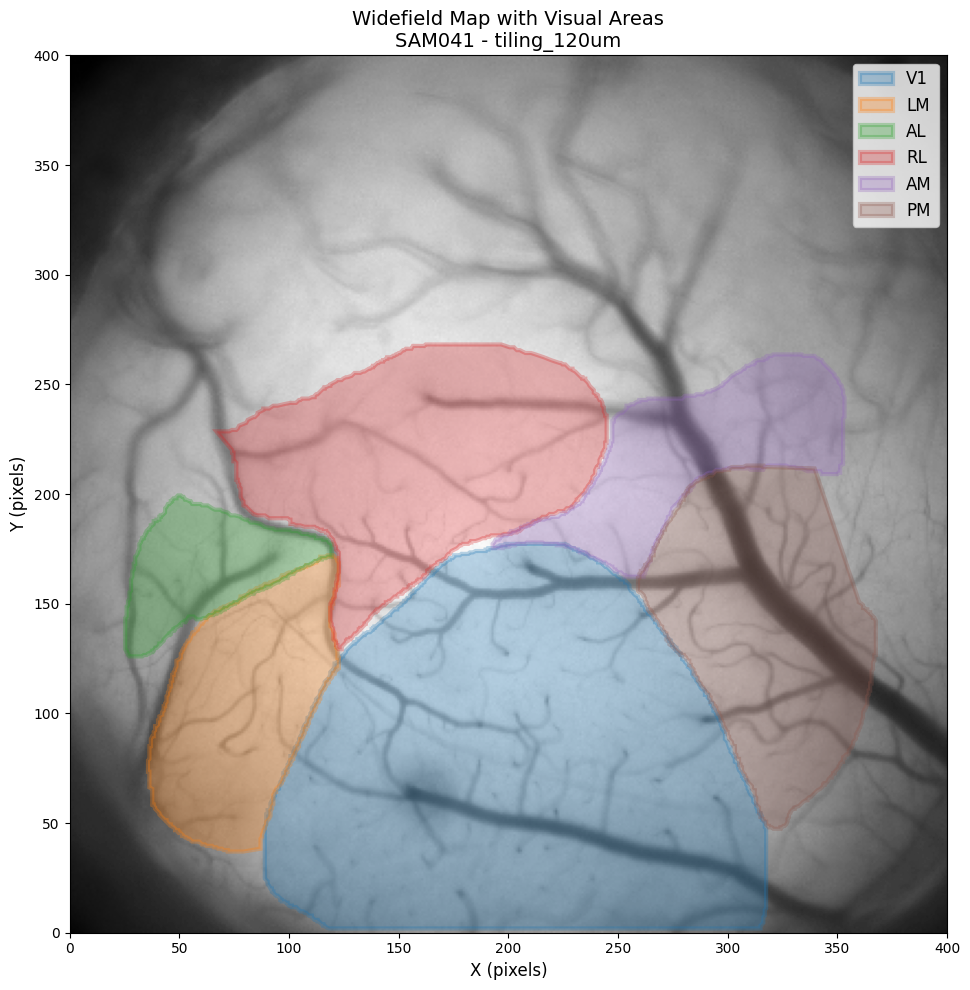

(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'center': 'Widefield Map with Visual Areas\nSAM041 - tiling_120um'}, xlabel='X (pixels)', ylabel='Y (pixels)'>)

In [23]:
visualizer.plot_widefield_with_areas()

In [111]:
session_df_path = r"D:\data-distance-coding-project\processed-data\251126_SAM041_tiling_1_120um\251126_SAM041_tiling_1_120um_dataframe_registered.pkl"
session_df = pickle.load(open(session_df_path, 'rb'))

Suite2p stat loaded from D:\data-distance-coding-project\processed-data\251126_SAM041_tiling_1_120um\suite2p\plane0\stat.npy


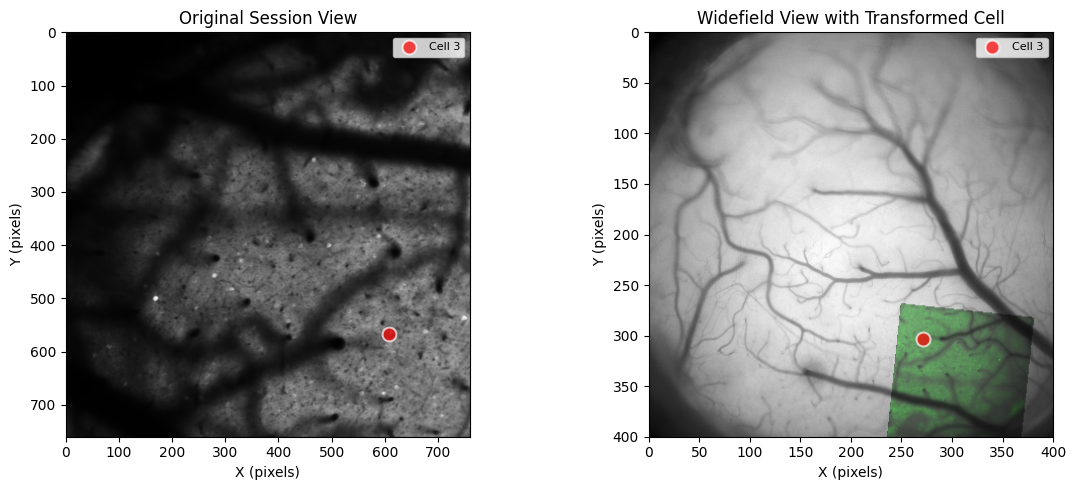

Suite2p stat loaded from D:\data-distance-coding-project\processed-data\251126_SAM041_tiling_1_120um\suite2p\plane0\stat.npy
270.9541456189771 303.6500896331187


In [28]:
fig = mapper.plot_cell_in_widefield('251126_SAM041_tiling_1_120um', 3)
suite2p_stat = mapper.load_suite2p_stat('251126_SAM041_tiling_1_120um')
xpix_raw, ypix_raw = mapper.get_original_coords(suite2p_stat, cell_id=3)
xwf, ywf = mapper.transform_coords_to_widefield('251126_SAM041_tiling_1_120um', xpix_raw, ypix_raw)
print(xwf, ywf)

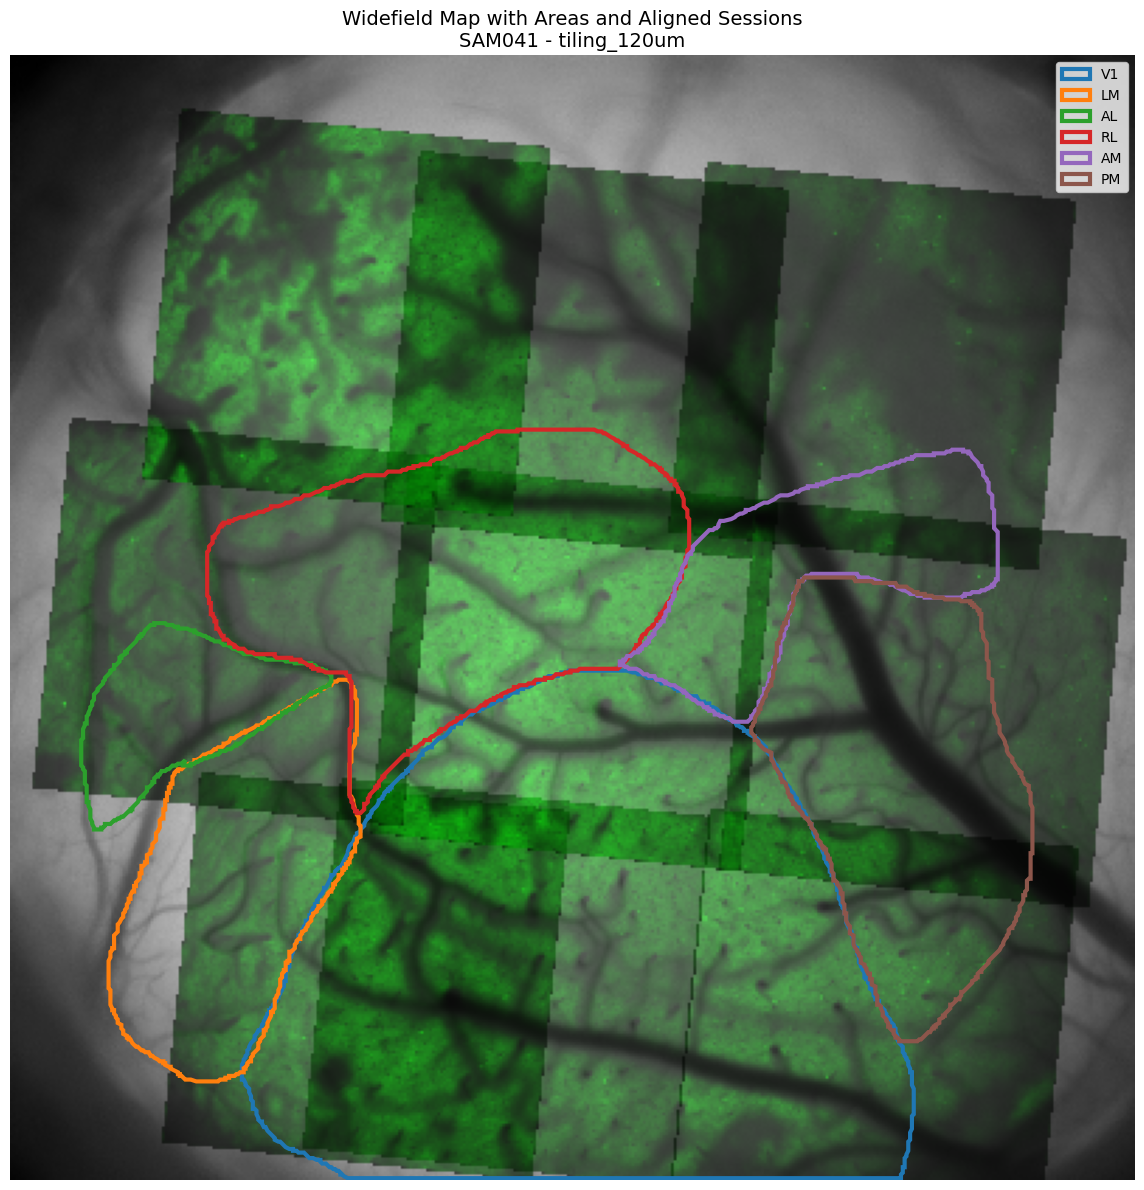

(<Figure size 1200x1200 with 1 Axes>,
 <Axes: title={'center': 'Widefield Map with Areas and Aligned Sessions\nSAM041 - tiling_120um'}, xlabel='X (pixels)', ylabel='Y (pixels)'>)

In [31]:
visualizer.plot_widefield_with_areas_and_sessions()

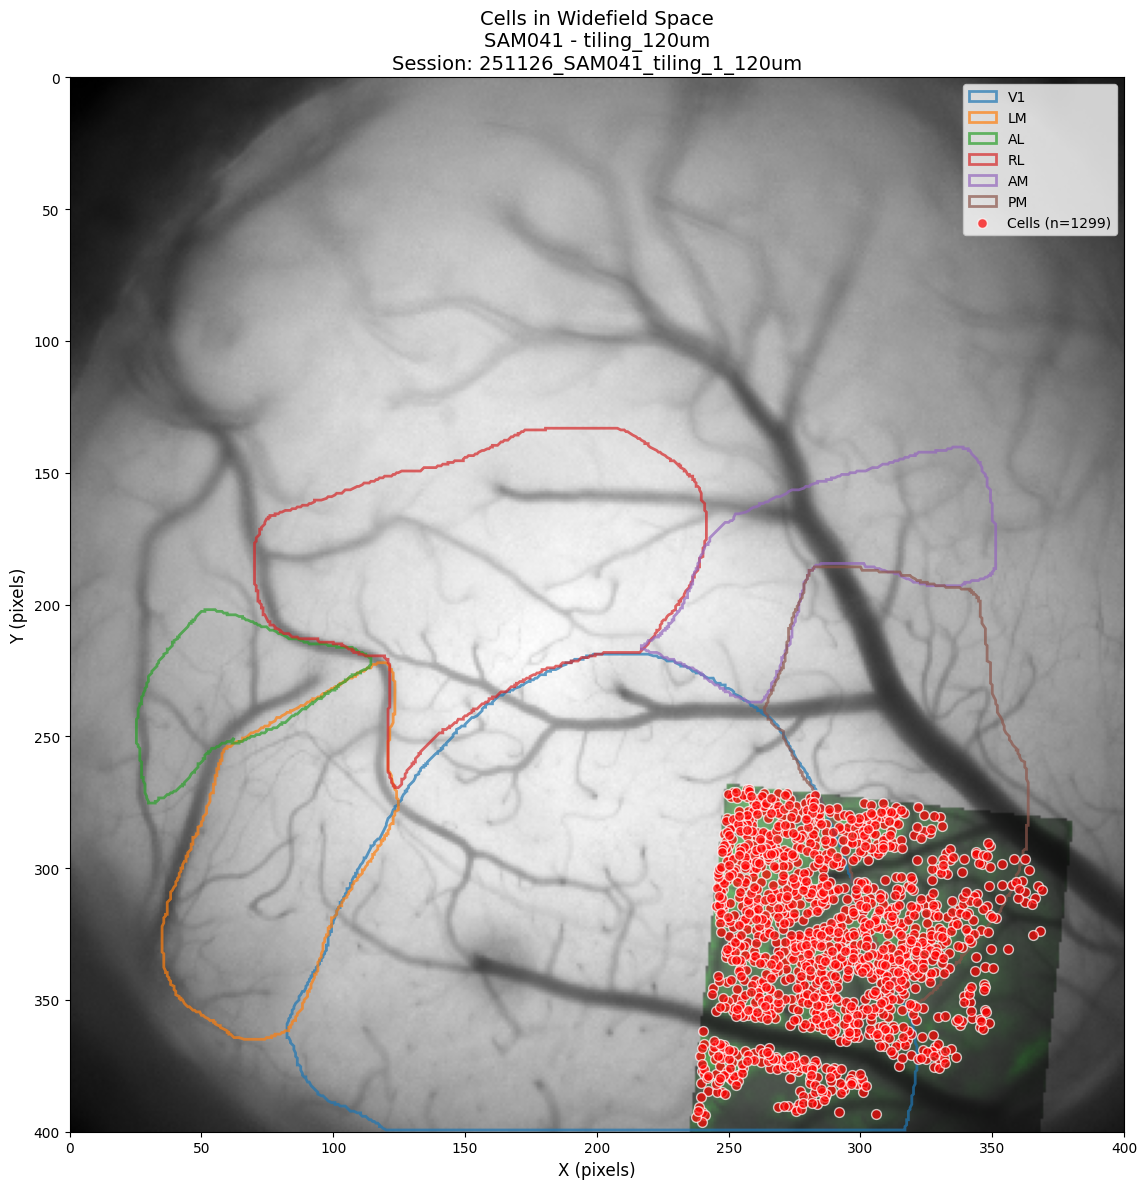

(<Figure size 1200x1200 with 1 Axes>,
 <Axes: title={'center': 'Cells in Widefield Space\nSAM041 - tiling_120um\nSession: 251126_SAM041_tiling_1_120um'}, xlabel='X (pixels)', ylabel='Y (pixels)'>)

In [30]:
visualizer.plot_cells_in_widefield(session_df, '251126_SAM041_tiling_1_120um')

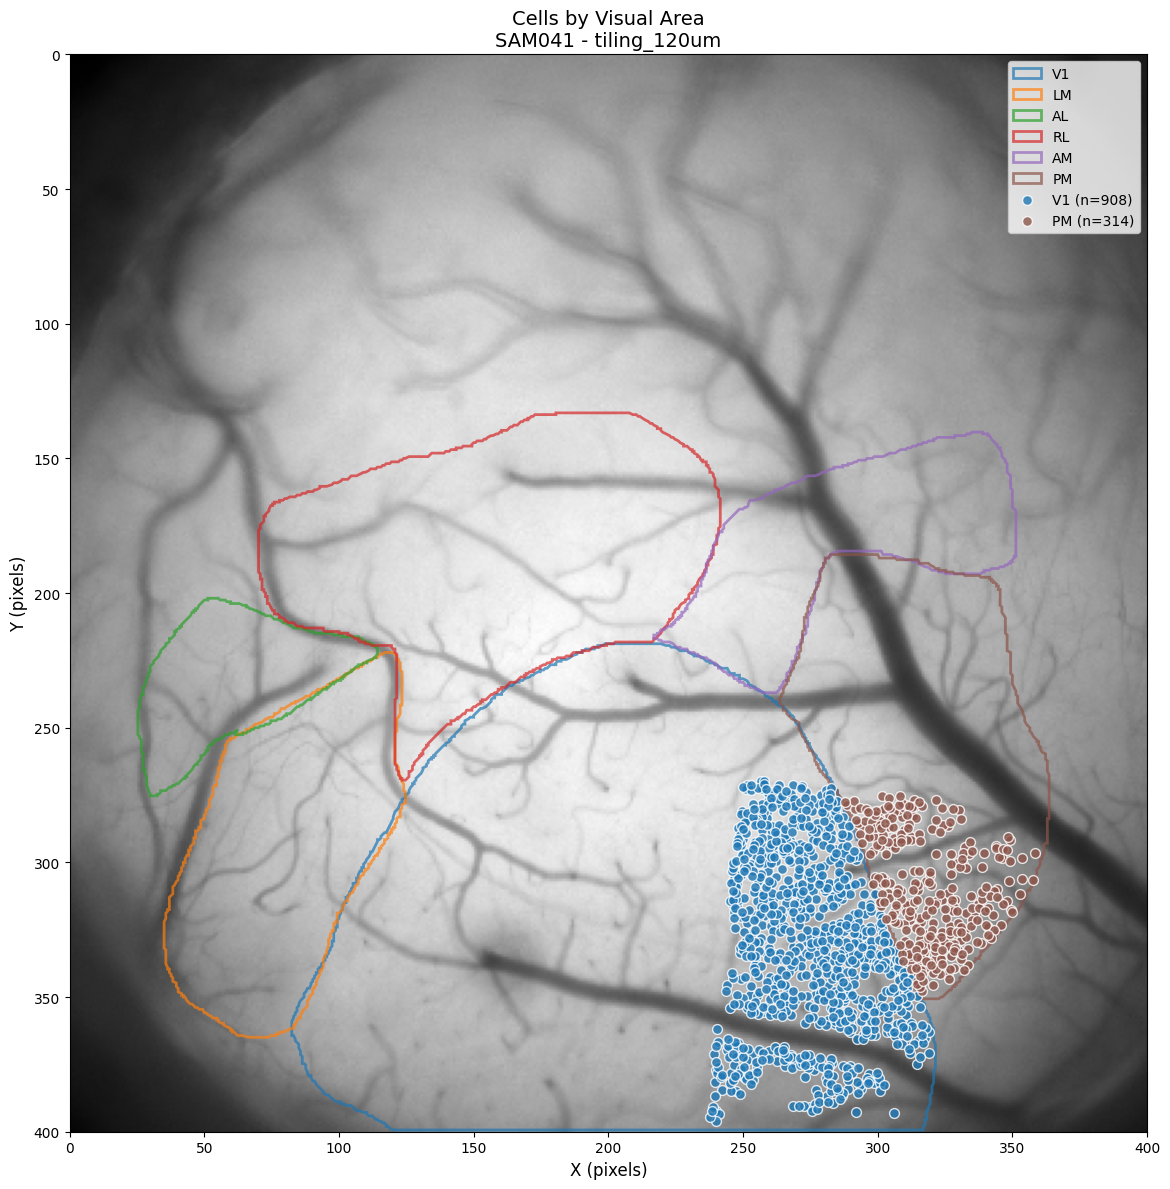

(<Figure size 1200x1200 with 1 Axes>,
 <Axes: title={'center': 'Cells by Visual Area\nSAM041 - tiling_120um'}, xlabel='X (pixels)', ylabel='Y (pixels)'>)

In [33]:
visualizer.plot_cells_by_area(session_df)